🚀 Device: cpu
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⏳ Загрузка данных... (OULAD)
✅ Файлы считаны. Feature Engineering...
✅ Датасет готов. Студентов: 22058. Распределение классов: [ 6676 15382]

⚡ Запуск: Static (Demo)


Static (Demo):   0%|          | 0/15 [00:00<?, ?it/s]

   ✅ Done. Best Weighted F1: 0.8515

⚡ Запуск: Dynamic (VLE)


Dynamic (VLE):   0%|          | 0/15 [00:00<?, ?it/s]

   ✅ Done. Best Weighted F1: 0.8871

⚡ Запуск: Hybrid (Imbalanced)


Hybrid (Imbalanced):   0%|          | 0/30 [00:00<?, ?it/s]

   ✅ Done. Best Weighted F1: 0.9076

⚡ Запуск: Hybrid (Balanced)


Hybrid (Balanced):   0%|          | 0/30 [00:00<?, ?it/s]

   ✅ Done. Best Weighted F1: 0.9071

📊 TABLE 1: Comparative Analysis of Predictive Vectors (Real Data)
        Metric  Static Vector  Behavioral Vector  Hybrid Model
      Accuracy         0.8511             0.8901        0.9068
  F1-Score (W)         0.8515             0.8871        0.9071
       ROC-AUC         0.9147             0.9096        0.9601
Train Time (s)        12.0514            81.3493      968.8654

⚖️ TABLE 2: Impact of Class Balancing (Recall Analysis)
           Processing Pipeline  Recall (Class 0 - Fail)  F1-Score (Weighted)  Class 0 Support
    Baseline (Imbalanced Loss)                   0.8037               0.9076           1335.0
OULAD-Ultimate (Weighted Loss)                   0.8554               0.9071           1335.0


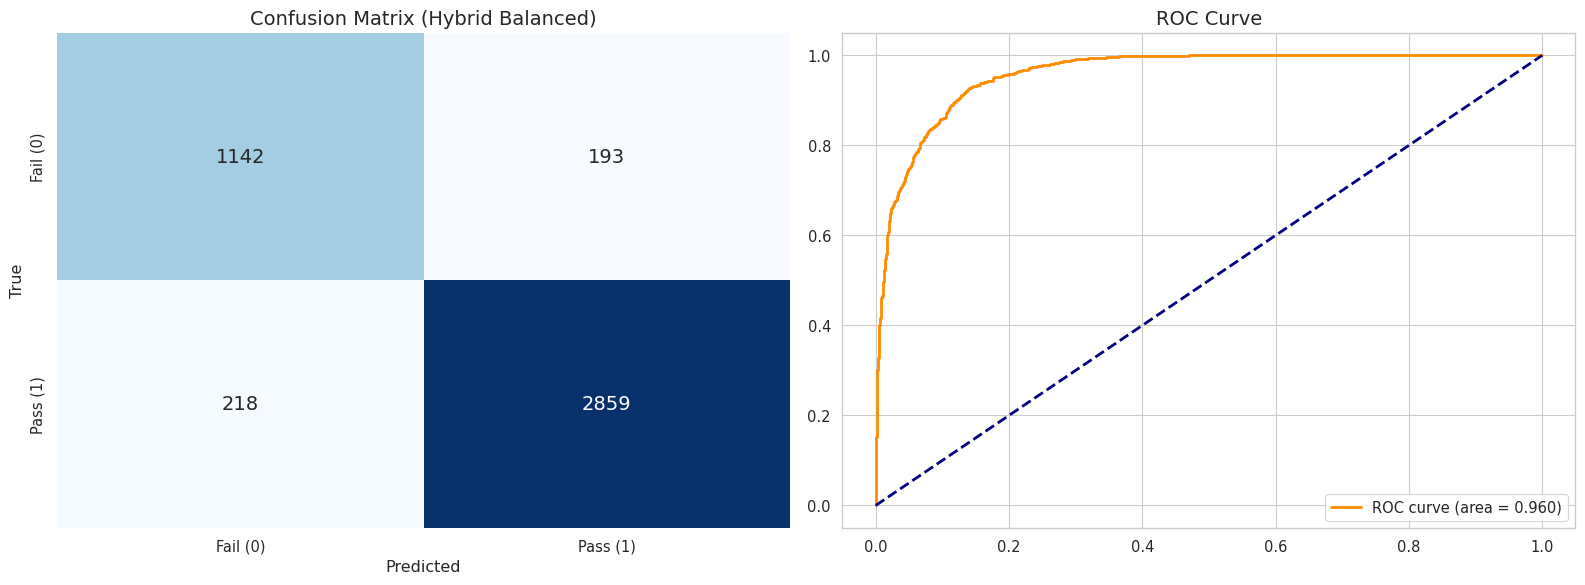

⏳ Computing t-SNE... (may take 30s)


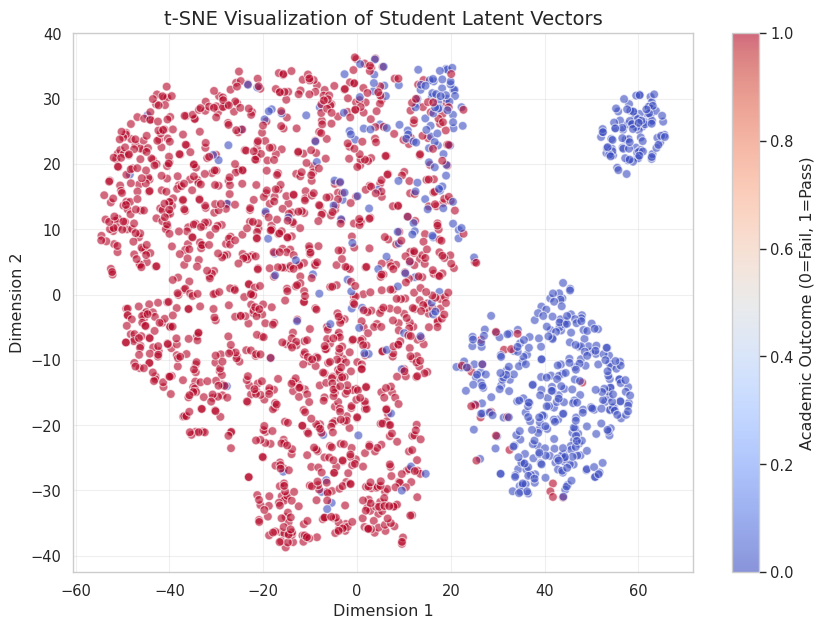

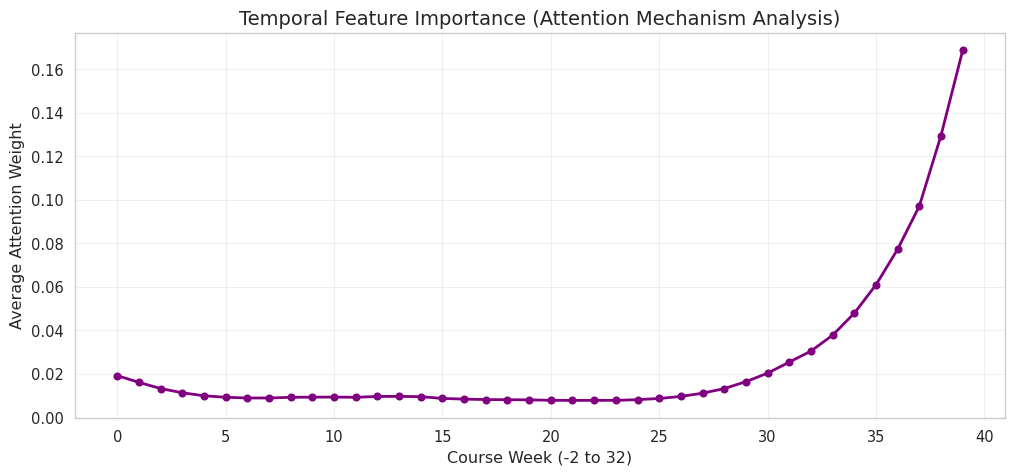

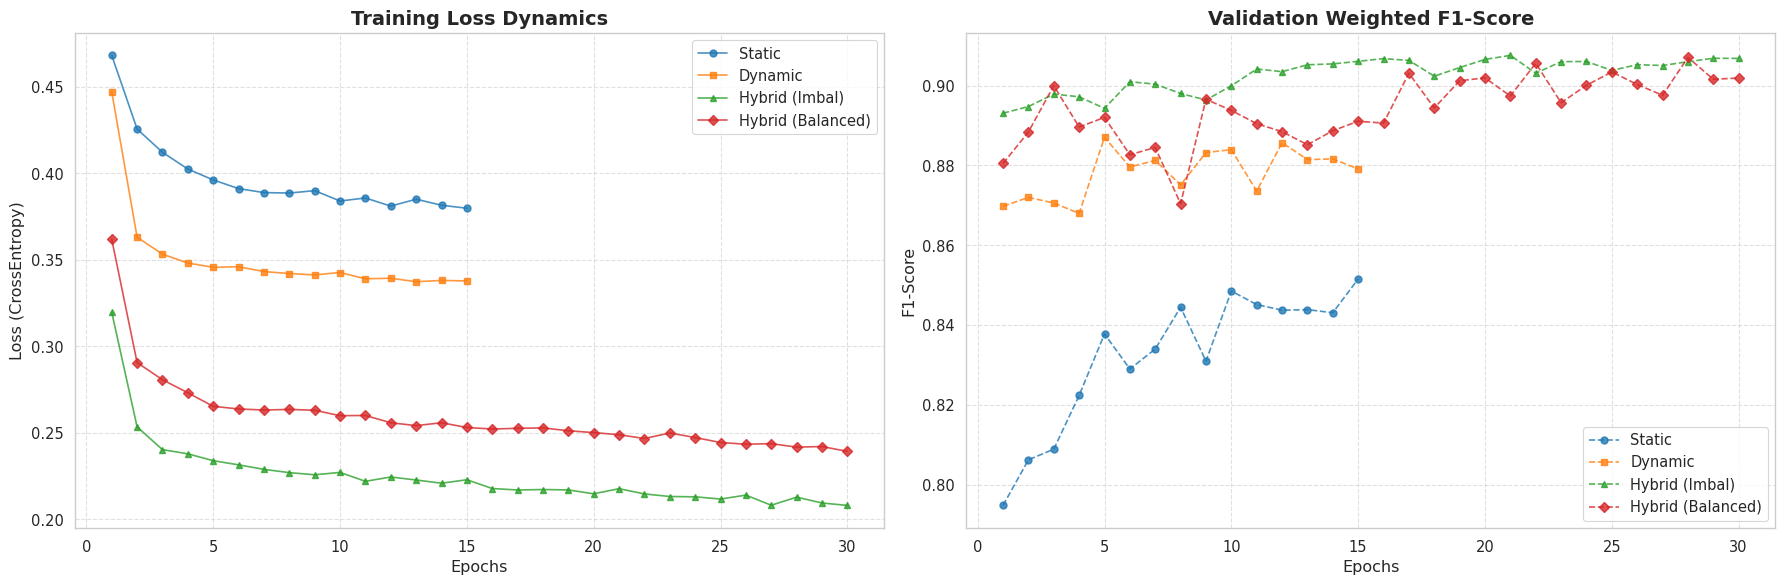

In [8]:
# ==========================================
# 1. ИМПОРТЫ И НАСТРОЙКИ ОКРУЖЕНИЯ
# ==========================================
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
import time
import copy
import warnings
from tqdm.auto import tqdm
from google.colab import drive
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             confusion_matrix, precision_recall_curve,
                             recall_score, classification_report)
from sklearn.utils import class_weight
from sklearn.manifold import TSNE

warnings.filterwarnings('ignore')

# Настройка устройства
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🚀 Device: {device}")

# Настройка стиля графиков
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

# ==========================================
# 2. ЗАГРУЗКА ДАННЫХ
# ==========================================
drive.mount('/content/drive')

# ⚠️ УКАЖИТЕ ПРАВИЛЬНЫЙ ПУТЬ К ПАПКЕ
DATA_PATH = '/content/drive/MyDrive'

def get_data(path):
    print("⏳ Загрузка данных... (OULAD)")

    # Чтение файлов
    try:
        info = pd.read_csv(f'{path}/studentInfo.csv')
        vle = pd.read_csv(f'{path}/studentVle.csv')
        assess = pd.read_csv(f'{path}/studentAssessment.csv')
        assess_info = pd.read_csv(f'{path}/assessments.csv')
    except FileNotFoundError:
        raise FileNotFoundError(f"❌ Файлы не найдены в {path}. Проверьте путь.")

    # Создание UID
    def create_uid(df):
        return df['id_student'].astype(str) + "_" + df['code_module'] + "_" + df['code_presentation']

    info['uid'] = create_uid(info)
    vle['uid'] = create_uid(vle)

    assess = assess.merge(assess_info, on='id_assessment', how='left')
    assess['uid'] = create_uid(assess)

    print("✅ Файлы считаны. Feature Engineering...")

    # 1. Агрегация оценок (Static features)
    assess_features = assess.groupby('uid').agg({
        'score': ['mean', 'max', 'min'],
        'date_submitted': ['count']
    })
    assess_features.columns = ['mean_score', 'max_score', 'min_score', 'submit_count']
    assess_features = assess_features.fillna(0)

    # 2. Временные ряды кликов (Dynamic features)
    # Фильтруем семестр (0-240 дней) и биннинг по неделям
    vle = vle[(vle['date'] >= -20) & (vle['date'] < 260)]
    vle['week'] = pd.cut(vle['date'], bins=np.arange(-21, 266, 7), labels=False)

    # Pivot table: Строки=UID, Столбцы=Недели, Значения=Клики
    vle_pivot = vle.pivot_table(index='uid', columns='week', values='sum_click', aggfunc='sum', fill_value=0)

    # Выравнивание длины до 35 недель
    full_weeks = pd.DataFrame(index=vle_pivot.index, columns=range(35)).fillna(0)
    vle_final = full_weeks.add(vle_pivot, fill_value=0).fillna(0)

    # 3. Таргет и Демография
    info = info[info['final_result'] != 'Withdrawn'] # Работаем с бинарной классификацией Pass vs Fail
    info['target'] = info['final_result'].apply(lambda x: 1 if x in ['Pass', 'Distinction'] else 0)

    # Label Encoding
    cat_cols = ['gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']
    for col in cat_cols:
        le = LabelEncoder()
        info[col] = le.fit_transform(info[col])

    # 4. Merge
    # Пересечение студентов, у которых есть и инфо, и клики
    common_uids = info['uid'][info['uid'].isin(vle_final.index)].values

    info = info.set_index('uid').loc[common_uids]
    vle_final = vle_final.loc[common_uids]
    info = info.join(assess_features, how='left').fillna(0)

    # Формирование массивов
    static_cols = cat_cols + ['num_of_prev_attempts', 'studied_credits', 'mean_score', 'max_score', 'submit_count']
    X_static = info[static_cols].values
    X_dynamic = vle_final.values
    y = info['target'].values

    print(f"✅ Датасет готов. Студентов: {len(y)}. Распределение классов: {np.bincount(y)}")
    return X_static, X_dynamic, y

# Загрузка
try:
    X_s_raw, X_d_raw, y = get_data(DATA_PATH)
except Exception as e:
    print(e)
    # Останавливаем выполнение, если данных нет
    raise SystemExit("Остановка: проверьте путь к данным.")

# ==========================================
# 3. SPLIT & SCALING
# ==========================================
X_s_tr, X_s_te, X_d_tr, X_d_te, y_tr, y_te = train_test_split(
    X_s_raw, X_d_raw, y, test_size=0.2, stratify=y, random_state=42
)

# Scaling
scaler_s = StandardScaler()
X_s_tr = scaler_s.fit_transform(X_s_tr)
X_s_te = scaler_s.transform(X_s_te)

scaler_d = RobustScaler()
X_d_tr = scaler_d.fit_transform(X_d_tr)
X_d_te = scaler_d.transform(X_d_te)

# DataLoaders
train_ds = TensorDataset(torch.FloatTensor(X_s_tr), torch.FloatTensor(X_d_tr), torch.LongTensor(y_tr))
test_ds = TensorDataset(torch.FloatTensor(X_s_te), torch.FloatTensor(X_d_te), torch.LongTensor(y_te))

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256)

# ==========================================
# 4. АРХИТЕКТУРЫ МОДЕЛЕЙ
# ==========================================

# --- A. Static Baseline (MLP) ---
class StaticBaseline(nn.Module):
    def __init__(self, static_dim):
        super(StaticBaseline, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(static_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )
    def forward(self, x_s, x_d):
        return self.net(x_s)

# --- B. Dynamic Baseline (Simple LSTM) ---
class DynamicBaseline(nn.Module):
    def __init__(self, seq_len):
        super(DynamicBaseline, self).__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 2)

    def forward(self, x_s, x_d):
        x_d = x_d.unsqueeze(-1)
        _, (h_n, _) = self.lstm(x_d)
        return self.fc(h_n[-1])

# --- C. Hybrid Model (OULAD-Ultimate) ---
class HybridModel(nn.Module):
    def __init__(self, static_dim, seq_len):
        super(HybridModel, self).__init__()
        # LSTM Branch
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=2,
                            batch_first=True, bidirectional=True, dropout=0.3)
        self.attn = nn.Linear(128, 1) # 128 = 64*2

        # Static Branch
        self.static_net = nn.Sequential(
            nn.Linear(static_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU()
        )

        # Fusion
        self.fc_final = nn.Sequential(
            nn.Linear(128 + 64, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x_s, x_d, return_embedding=False):
        x_d = x_d.unsqueeze(-1)

        # LSTM & Attention
        lstm_out, _ = self.lstm(x_d) # [Batch, Seq, 128]
        attn_weights = torch.softmax(self.attn(lstm_out), dim=1)
        context = torch.sum(attn_weights * lstm_out, dim=1) # [Batch, 128]

        # Static
        static_out = self.static_net(x_s) # [Batch, 64]

        # Concat
        combined = torch.cat((context, static_out), dim=1)

        if return_embedding:
            return combined

        return self.fc_final(combined)

# ==========================================
# 5. ЦИКЛ ОБУЧЕНИЯ
# ==========================================
def train_and_evaluate(model_name, model, train_loader, test_loader, epochs=15, use_weights=True):
    print(f"\n⚡ Запуск: {model_name}")
    start_time = time.time()

    model = model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=0.001)

    if use_weights:
        w = class_weight.compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
        cw = torch.FloatTensor(w).to(device)
        criterion = nn.CrossEntropyLoss(weight=cw)
    else:
        criterion = nn.CrossEntropyLoss()

    best_val_f1 = 0.0
    best_metrics = {}

    # Списки для хранения истории
    history = {'loss': [], 'f1': []}

    pbar = tqdm(range(epochs), desc=model_name, leave=True)

    for epoch in pbar:
        model.train()
        epoch_loss = 0.0
        for s_b, d_b, y_b in train_loader:
            s_b, d_b, y_b = s_b.to(device), d_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out = model(s_b, d_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # Средний лосс за эпоху
        avg_loss = epoch_loss / len(train_loader)
        history['loss'].append(avg_loss)

        # Eval
        model.eval()
        all_preds, all_probs, all_targets = [], [], []
        with torch.no_grad():
            for s_b, d_b, y_b in test_loader:
                s_b, d_b = s_b.to(device), d_b.to(device)
                out = model(s_b, d_b)
                probs = torch.softmax(out, dim=1)[:, 1]
                preds = torch.argmax(out, dim=1)

                all_probs.extend(probs.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(y_b.numpy())

        # Metrics
        f1 = f1_score(all_targets, all_preds, average='weighted')
        history['f1'].append(f1) # Сохраняем F1 для графика

        # Обновляем текст в прогресс-баре
        pbar.set_postfix({'loss': f"{avg_loss:.4f}", 'f1': f"{f1:.4f}"})

        if f1 > best_val_f1:
            best_val_f1 = f1
            best_metrics = {
                'Accuracy': accuracy_score(all_targets, all_preds),
                'F1-Score': f1,
                'ROC-AUC': roc_auc_score(all_targets, all_probs),
                'Recall_Risk_0': recall_score(all_targets, all_preds, pos_label=0),
                'History': history, # Добавляем историю в итоговый результат
                'Full_Report': classification_report(all_targets, all_preds, output_dict=True)
            }
            if "Hybrid (Balanced)" in model_name:
                torch.save(model.state_dict(), 'best_model.pth')

    total_time = time.time() - start_time
    best_metrics['Time'] = total_time
    print(f"   ✅ Done. Best Weighted F1: {best_val_f1:.4f}")
    return best_metrics

# ==========================================
# 6. ЭКСПЕРИМЕНТЫ (Training)
# ==========================================

# 1. Static Baseline
metrics_static = train_and_evaluate(
    'Static (Demo)', StaticBaseline(X_s_tr.shape[1]), train_loader, test_loader, epochs=15
)

# 2. Dynamic Baseline
metrics_dynamic = train_and_evaluate(
    'Dynamic (VLE)', DynamicBaseline(X_d_tr.shape[1]), train_loader, test_loader, epochs=15
)

# 3. Hybrid Imbalanced (для сравнения в Table 2)
metrics_imbal = train_and_evaluate(
    'Hybrid (Imbalanced)', HybridModel(X_s_tr.shape[1], X_d_tr.shape[1]),
    train_loader, test_loader, epochs=30, use_weights=False
)

# 4. Hybrid Balanced (Champion)
metrics_hybrid = train_and_evaluate(
    'Hybrid (Balanced)', HybridModel(X_s_tr.shape[1], X_d_tr.shape[1]),
    train_loader, test_loader, epochs=30, use_weights=True
)

# ==========================================
# 7. РЕЗУЛЬТАТЫ И ТАБЛИЦЫ
# ==========================================

# --- TABLE 1: Comparative Analysis ---
print("\n" + "="*70)
print("📊 TABLE 1: Comparative Analysis of Predictive Vectors (Real Data)")
print("="*70)

df_perf = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score (W)', 'ROC-AUC', 'Train Time (s)'],
    'Static Vector': [
        metrics_static['Accuracy'],
        metrics_static['F1-Score'],
        metrics_static['ROC-AUC'],
        metrics_static['Time']
    ],
    'Behavioral Vector': [
        metrics_dynamic['Accuracy'],
        metrics_dynamic['F1-Score'],
        metrics_dynamic['ROC-AUC'],
        metrics_dynamic['Time']
    ],
    'Hybrid Model': [
        metrics_hybrid['Accuracy'],
        metrics_hybrid['F1-Score'],
        metrics_hybrid['ROC-AUC'],
        metrics_hybrid['Time']
    ]
}).round(4)

print(df_perf.to_string(index=False))

# --- TABLE 2: Impact of Bias Correction ---
print("\n" + "="*60)
print("⚖️ TABLE 2: Impact of Class Balancing (Recall Analysis)")
print("="*60)
df_bias = pd.DataFrame({
    'Processing Pipeline': ['Baseline (Imbalanced Loss)', 'OULAD-Ultimate (Weighted Loss)'],
    'Recall (Class 0 - Fail)': [metrics_imbal['Recall_Risk_0'], metrics_hybrid['Recall_Risk_0']],
    'F1-Score (Weighted)': [metrics_imbal['F1-Score'], metrics_hybrid['F1-Score']],
    'Class 0 Support': [metrics_imbal['Full_Report']['0']['support'], metrics_hybrid['Full_Report']['0']['support']]
}).round(4)
print(df_bias.to_string(index=False))

# ==========================================
# 8. ВИЗУАЛИЗАЦИЯ (SCIENTIFIC PLOTS)
# ==========================================

# Загрузка лучшей модели
final_model = HybridModel(X_s_tr.shape[1], X_d_tr.shape[1]).to(device)
final_model.load_state_dict(torch.load('best_model.pth'))
final_model.eval()

# Получение данных для графиков
probs_final, preds_final, targets_final = [], [], []
embeddings = [] # Для t-SNE

with torch.no_grad():
    for s_b, d_b, y_b in test_loader:
        s_b, d_b = s_b.to(device), d_b.to(device)

        # Получаем и предсказания, и эмбеддинги
        out = final_model(s_b, d_b, return_embedding=False) # Logits
        emb = final_model(s_b, d_b, return_embedding=True)  # Latent vector

        probs_final.extend(torch.softmax(out, dim=1)[:, 1].cpu().numpy())
        preds_final.extend(torch.argmax(out, dim=1).cpu().numpy())
        targets_final.extend(y_b.numpy())
        embeddings.extend(emb.cpu().numpy())

probs_final = np.array(probs_final)
targets_final = np.array(targets_final)
embeddings = np.array(embeddings)

# --- FIGURE 1: CONFUSION MATRIX & ROC ---
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm = confusion_matrix(targets_final, preds_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0], cbar=False, annot_kws={"size": 14})
ax[0].set_title('Confusion Matrix (Hybrid Balanced)', fontsize=14)
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('True')
ax[0].set_xticklabels(['Fail (0)', 'Pass (1)'])
ax[0].set_yticklabels(['Fail (0)', 'Pass (1)'])

# ROC Curve
fpr, tpr, _ = roc_curve(targets_final, probs_final)
auc_val = roc_auc_score(targets_final, probs_final)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {auc_val:.3f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_title('ROC Curve', fontsize=14)
ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

# --- FIGURE 2: t-SNE LATENT SPACE ---
print("⏳ Computing t-SNE... (may take 30s)")
# Берем подвыборку 2000 точек для скорости
idx = np.random.choice(len(embeddings), min(2000, len(embeddings)), replace=False)
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
emb_2d = tsne.fit_transform(embeddings[idx])

plt.figure(figsize=(10, 7))
scatter = plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=targets_final[idx],
                      cmap='coolwarm', alpha=0.6, edgecolors='w', s=40)
plt.colorbar(scatter, label='Academic Outcome (0=Fail, 1=Pass)')
plt.title('t-SNE Visualization of Student Latent Vectors', fontsize=14)
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid(True, alpha=0.3)
plt.show()

# --- FIGURE 3: TEMPORAL ATTENTION (WEEK IMPORTANCE) ---
# Мы извлекаем веса внимания (Attention Weights) для тестового батча
# Чтобы понять, какие недели были самыми важными
with torch.no_grad():
    # Берем один батч
    s_b, d_b, _ = next(iter(test_loader))
    d_b = d_b.to(device).unsqueeze(-1)
    lstm_out, _ = final_model.lstm(d_b)
    # Считаем веса
    attn_weights = torch.softmax(final_model.attn(lstm_out), dim=1) # [Batch, 35, 1]
    # Усредняем по всем студентам в батче
    avg_attention = attn_weights.mean(dim=0).squeeze().cpu().numpy()

plt.figure(figsize=(12, 5))
plt.plot(range(len(avg_attention)), avg_attention, marker='o', color='purple', lw=2)
plt.title('Temporal Feature Importance (Attention Mechanism Analysis)', fontsize=14)
plt.xlabel('Course Week (-2 to 32)')
plt.ylabel('Average Attention Weight')
plt.grid(True, alpha=0.3)
plt.show()
def plot_comparative_learning(results_dict):
    """
    Рисует сетку графиков для всех моделей из словаря результатов.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

    # Цвета для моделей
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    markers = ['o', 's', '^', 'D']

    for (name, metrics), color, marker in zip(results_dict.items(), colors, markers):
        hist = metrics['History']
        epochs = range(1, len(hist['loss']) + 1)

        # График лосса
        ax1.plot(epochs, hist['loss'], label=name, color=color,
                 marker=marker, markersize=5, linestyle='-', alpha=0.8)

        # График F1-Score
        ax2.plot(epochs, hist['f1'], label=name, color=color,
                 marker=marker, markersize=5, linestyle='--', alpha=0.8)

    # Настройка осей Лосса
    ax1.set_title('Training Loss Dynamics', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss (CrossEntropy)')
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()

    # Настройка осей F1
    ax2.set_title('Validation Weighted F1-Score', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('F1-Score')
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend()

    plt.tight_layout()
    plt.show()

# ПОСЛЕ ОБУЧЕНИЯ МОДЕЛЕЙ ВЫЗОВИТЕ ЭТОТ КОД:
results_to_plot = {
    'Static': metrics_static,
    'Dynamic': metrics_dynamic,
    'Hybrid (Imbal)': metrics_imbal,
    'Hybrid (Balanced)': metrics_hybrid
}

plot_comparative_learning(results_to_plot)